# Journal 2 - Scoring and baselines

**Question.** What must a model beat to be worth deploying?
**Answer.** B2 (TF-IDF + logistic regression): on `test_natural` it finds the right desk for 92 % of tickets, yet **34 tickets in 100 get a definite answer that is wrong** (a silent error), and 6.6 % of urgent tickets go to the wrong desk. It breaks on the extraction traps (missing currency, odd id formats).

How a ticket is judged (`docs/scoring_protocol.md`): the copilot routes it by itself when sure, and hands it to a human otherwise. A ticket handed to a human costs a little work. A **silent error** (routed to a desk with a wrong desk or a wrong reference) is the worst: nothing flags it and the draft is built on it. The error severity score (human = 1, wrong desk = 3, wrong reference = 5, urgent ticket in a wrong desk = 10 points; assumed weights) summarises it in one number.

The four measures read in every journal:

| Measure | Meaning | Direction |
|---|---|---|
| Silent error | the ticket is routed by itself, but to a wrong desk or with a wrong reference; nothing flags it | lower is better |
| Sent to a person without need | the ticket has a desk, yet the answer hands it to a person (the Re-router in the product flow), invalid JSON included | lower is better |
| Urgent in a wrong desk | a reference `high` ticket routed by itself to a wrong desk | lower is better |
| Auto-routed / desk accuracy | share routed without a person / share whose initial action is right | higher is better |

In [1]:
import json, sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "research/qualifier/src/dataset_build").is_dir())
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks/qualifier")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import _viz as viz
import _tracking
viz.setup()

from research.qualifier.src import scoring
from research.qualifier.src.baselines import predict_majority, predict_rules, fit_tfidf, predict_tfidf
print(scoring.DEFAULT_WEIGHTS)

SeverityWeights(triage=1.0, wrong_desk=3.0, wrong_reference=5.0, wrong_desk_urgent=10.0)


## 1. Does the scorer behave? Two trivial systems on val
A perfect system must have no error at all; sending everything to a human must give no silent error, and a severity of 1 point for each ticket that has a desk (83 % of them), so 0.83.

In [2]:
from research.qualifier.src.dataset_build.schema import TicketLabel
val_x, val_y, _ = scoring.load_split(ROOT / "data/dataset/val.csv")
train_x, train_y, _ = scoring.load_split(ROOT / "data/dataset/train.csv")
perfect = [json.dumps(l.model_dump()) for l in val_y]
triage = json.dumps(TicketLabel(intent="OTHER", sub_intent="OTHER", transaction_id="", amount="", currency="",
                                urgency="UNDEFINED", sentiment="UNDEFINED").model_dump())
pd.DataFrame({"perfect": scoring.score(val_y, perfect), "all to a human": scoring.score(val_y, [triage] * len(val_y))}).loc[
    ["silent_error_rate", "needless_triage_rate", "auto_routed_rate", "desk_accuracy", "severity_score"]].round(3)

,perfect,all to a human
silent_error_rate,0.000,0.000
needless_triage_rate,0.000,0.833
auto_routed_rate,0.833,0.000
desk_accuracy,1.000,0.167
severity_score,0.000,0.833


Both behave as designed, so the scale is trustworthy. Note that the perfect system routes only 83 % of the tickets by itself: the other 17 % are `OTHER` or `UNDEFINED` and belong to a human.

## 2. The three baselines on val
B0 majority class, B1 keywords + regexes, B2 TF-IDF + logistic regression (regularisation `C` chosen on val only).

In [3]:
SHOWN = ["silent_error_rate", "needless_triage_rate", "urgent_wrong_desk", "auto_routed_rate", "desk_accuracy",
         "exact_transaction_id", "exact_amount", "severity_score"]
grid = {c: scoring.score(val_y, predict_tfidf(fit_tfidf(train_x, train_y, c), val_x))["severity_score"] for c in (0.3, 1.0, 3.0, 10.0)}
best_c = min(grid, key=grid.get)
val = {"B0": scoring.score(val_y, predict_majority(train_y, val_x)), "B1": scoring.score(val_y, predict_rules(val_x)),
       "B2": scoring.score(val_y, predict_tfidf(fit_tfidf(train_x, train_y, best_c), val_x))}
print("severity score by C:", {c: round(v, 3) for c, v in grid.items()}, "-> kept C =", best_c)
pd.DataFrame(val).loc[SHOWN].round(3)

severity score by C: {0.3: 1.874, 1.0: 1.631, 3.0: 1.519, 10.0: 1.478} -> kept C = 10.0


,B0,B1,B2
silent_error_rate,0.812,0.468,0.283
needless_triage_rate,0.000,0.208,0.007
urgent_wrong_desk,0.759,0.392,0.076
auto_routed_rate,1.000,0.734,0.863
desk_accuracy,0.215,0.403,0.949
exact_transaction_id,0.648,0.894,0.894
exact_amount,0.642,0.829,0.829
severity_score,3.925,2.509,1.478


B0 is the floor: it answers every ticket and is wrong on most. B1 hands a quarter of the tickets to a human and still gets the desk right only 40 % of the time. B2 is a real competitor (95 % desk accuracy) but a third of its definite answers carry a wrong desk or a wrong reference. The reference fields (id, amount) are extracted by the same regexes in B1 and B2: that is where a language model has room to win.

## 3. The baselines on `test_natural` (read once)
610 tickets, written by another model than train. Interval = 95 % bootstrap.

In [4]:
nat_x, nat_y, nat_traps = scoring.load_split(ROOT / "data/dataset/test_natural.csv")
models = fit_tfidf(train_x, train_y, best_c)
preds = {"B0": predict_majority(train_y, nat_x), "B1": predict_rules(nat_x), "B2": predict_tfidf(models, nat_x)}
res = {k: scoring.score(nat_y, v) for k, v in preds.items()}
ci = {k: scoring.mean_interval(scoring.silent_errors(nat_y, v)) for k, v in preds.items()}
display(pd.DataFrame(res).loc[SHOWN].round(3))
print("silent errors per 100, 95 % interval:", {k: f"{100 * v[0]:.1f} [{100 * v[1]:.1f}, {100 * v[2]:.1f}]" for k, v in ci.items()})

,B0,B1,B2
silent_error_rate,0.785,0.403,0.339
needless_triage_rate,0.000,0.241,0.003
urgent_wrong_desk,0.778,0.335,0.066
auto_routed_rate,1.000,0.685,0.905
desk_accuracy,0.236,0.446,0.916
exact_transaction_id,0.648,0.895,0.895
exact_amount,0.633,0.802,0.802
severity_score,3.890,2.274,1.666


silent errors per 100, 95 % interval: {'B0': '78.5 [75.2, 81.6]', 'B1': '40.3 [36.4, 44.1]', 'B2': '33.9 [30.0, 37.9]'}


B2 > B1 > B0 in quality, as expected, but even B2 routes 6.6 % of the urgent tickets to the wrong desk (11 of 167), the costliest error. Error severity score: B2 1.67, B1 2.27, B0 3.89 points.

## 4. The traps: where does B2 break?
`test_traps` has 23 trap families (380 tickets). Counts only below 20 tickets, no interval.

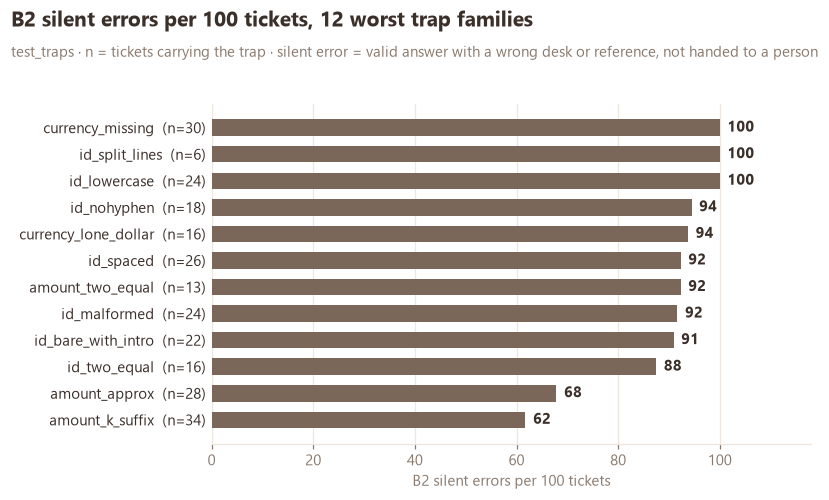

trap families where B2 has at least 80 silent errors per 100: 10 of 23


In [5]:
trap_x, trap_y, trap_tags = scoring.load_split(ROOT / "data/dataset/test_traps.csv")
b2 = pd.DataFrame(scoring.silent_by_trap(trap_y, predict_tfidf(models, trap_x), trap_tags), index=["n", "rate"]).T
top = b2.sort_values("rate", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
viz.hbar(ax, [f"{k}  (n={int(n)})" for k, n in zip(top.index, top["n"])], (100 * top["rate"]).tolist(),
         [viz.SYSTEM_COLORS["B2"]] * len(top), fmt="{:.0f}")
ax.set_xlabel("B2 silent errors per 100 tickets")
viz.headline(fig, "B2 silent errors per 100 tickets, 12 worst trap families", f"test_traps · n = tickets carrying the trap · {viz.SILENT}")
viz.save(fig, "02_b2_traps")
plt.show()
print("trap families where B2 has at least 80 silent errors per 100:", int((b2["rate"] >= 0.8).sum()), "of", len(b2))

B2 still finds the right desk (accuracy mostly 0.9-1.0) but fails to extract the reference: missing currency, lowercase or spaced ids, two amounts. A model that *reads* the ticket should fix exactly this.

**Bar for the next journal: fewer than 34 silent errors per 100 tickets and fewer than 6.6 % of urgent tickets in a wrong desk.**

## 5. Base model versus fine-tuning on validation

B3 is the prompted Qwen2.5-3B base model; D uses the same base model after LoRA fine-tuning. Both receive exactly the same prompt, printed below, so the gap measures the fine-tuning and nothing else. Predictions load from MLflow when available and otherwise from the locally validated exports.

In [6]:
from research.qualifier.src.prompt import INSTRUCTION, build_user_message
print("There is no separate system turn: the Qwen2.5 chat template adds its default system line, and the user turn is the instruction followed by the ticket.\n")
print(build_user_message(val_x[0]))

There is no separate system turn: the Qwen2.5 chat template adds its default system line, and the user turn is the instruction followed by the ticket.

You read one support ticket sent by a merchant of a B2B payments company, in French or English. Answer with one JSON object and nothing else, with exactly these keys, all string values: intent (payment_status, dispute, technical_api, compliance, OTHER or UNDEFINED), sub_intent (one of: payment_status: delayed_credit, missing_payment, status_inquiry, refund_status; dispute: unauthorised_fee, chargeback, duplicate_charge, amount_mismatch; technical_api: webhook_down, api_error, auth_failure, integration_question; compliance: kyc_update, account_hold, document_request, regulatory_question; or OTHER or UNDEFINED), transaction_id (TX- followed by 6 digits, or empty), amount (a decimal with a dot and two decimals, no thousands separator, or empty), currency (one of EUR, USD, GBP, CHF, CAD, SEK, DKK, NOK, PLN, or empty), urgency (high, medium,


[!] MLFLOW TRACKING NOTICE: Server unreachable at: http://127.0.0.1:5000
    (Connectivity check timed out in 0.1s to prevent notebook freeze)

    -> Local fallback active: reading predictions and metrics directly
       from local CSV files in `docs/results/`.

    INFO: To start the local MLflow server and enable live tracking:
       1. Open a separate terminal
       2. Run: mlflow server --host 127.0.0.1 --port 5000
          (or: uv run mlflow server --port 5000)

Using local historical prediction file: data\runs\base_val_predictions.csv
Using local historical prediction file: docs\results\d_qwen2.5-3b_full_run_val_predictions.csv


,B2,B3,D
silent_error_rate,0.283,0.085,0.007
urgent_wrong_desk,0.076,0.013,0.000
severity_score,1.478,0.846,0.027
desk_accuracy,0.949,0.532,0.986
auto_routed_rate,0.863,0.413,0.833


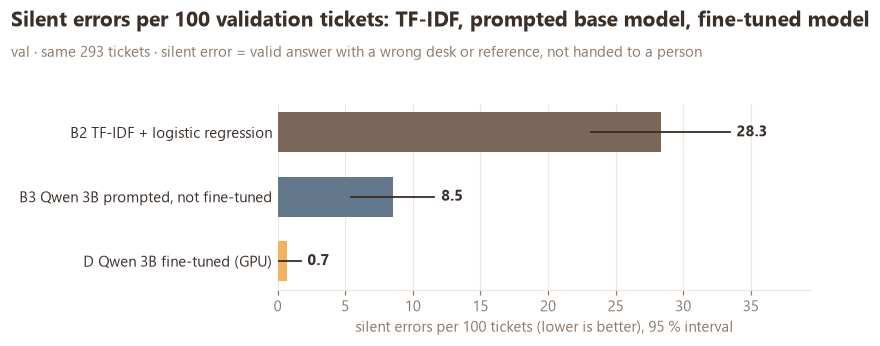

In [7]:
fallbacks = {'B3': ROOT / 'data/runs/base_val_predictions.csv',
             'D': ROOT / 'docs/results/d_qwen2.5-3b_full_run_val_predictions.csv'}
val_compare = {'B2': val['B2']}
val_flags = {'B2': scoring.silent_errors(val_y, predict_tfidf(fit_tfidf(train_x, train_y, best_c), val_x))}
for system, fallback in fallbacks.items():
    predictions = _tracking.load_predictions(ROOT, system, 'val', fallback, val_x)
    if predictions is None:
        print(f'{system}/val unavailable; omitted')
        continue
    val_compare[system] = scoring.score(val_y, predictions)
    val_flags[system] = scoring.silent_errors(val_y, predictions)
display(pd.DataFrame(val_compare).loc[['silent_error_rate','urgent_wrong_desk','severity_score','desk_accuracy','auto_routed_rate']].round(3))
order = [system for system in ('B2','B3','D') if system in val_compare]
intervals = {system: scoring.mean_interval(val_flags[system]) for system in order}
fig, ax = plt.subplots(figsize=(7.5, 3.2))
viz.hbar(ax, [viz.LABELS[s] for s in order], [100*intervals[s][0] for s in order], [viz.SYSTEM_COLORS[s] for s in order],
         fmt='{:.1f}', errors=[(100*intervals[s][1],100*intervals[s][2]) for s in order])
ax.set_xlabel('silent errors per 100 tickets (lower is better), 95 % interval')
viz.headline(fig, 'Silent errors per 100 validation tickets: TF-IDF, prompted base model, fine-tuned model', f'val · same 293 tickets · {viz.SILENT}')
viz.save(fig, '02_val_base_vs_finetuned')
plt.show()

### Same ticket, two answers
The first validation ticket where the prompted base model fails and the fine-tuned model is right.

In [8]:
b3_raw = _tracking.load_predictions(ROOT, "B3", "val", fallbacks["B3"], val_x)
d_raw = _tracking.load_predictions(ROOT, "D", "val", fallbacks["D"], val_x)
k = next(j for j in range(len(val_y)) if scoring.silent_errors(val_y[j:j + 1], b3_raw[j:j + 1])[0] or scoring.parse_output(b3_raw[j]) is None
         if scoring.parse_output(d_raw[j]) == val_y[j])
print(f"--- ticket {k}\n{val_x[k]}\n")
print("--- reference\n" + val_y[k].model_dump_json(indent=1))
print("\n--- B3, prompted base model\n" + b3_raw[k])
print("\n--- D, fine-tuned\n" + d_raw[k])

--- ticket 0
hey, i need a certificate or attestation or some kind of compliance statement from you for my shop, and i need it now because my business activity is completely blocked on my end. the payment in question is TX 688 116 for €1,373.20 and i can't move anything until i have that document in hand. i've been going back and forth with your support and nobody has sent me anything usable, which is honestly ridiculous for a payments company. if i don't get this statement sorted i'm going to have to escalate this and seriously consider moving my business somewhere else. just tell me what you need from me and send the document, i'll fill in whatever form you want. i'm a small retail owner, i don't have a compliance team to chase this for me, so please just help me get unblocked.

--- reference
{
 "intent": "compliance",
 "sub_intent": "document_request",
 "transaction_id": "TX-688116",
 "amount": "1373.20",
 "currency": "EUR",
 "urgency": "high",
 "sentiment": "negative"
}

--- B3, pr